### EMT-TF panel — expression, pseudotime trend, arm end (data-driven)\nFor each detected TF: expressing fraction, mean early/late, Spearman vs pseudotime. Keep only factors expressed in >3% of cells and display the two spanning the observed trend, each labelled by its **own** mean-early/mean-late classification — not assumed to be root- vs terminus-loaded.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 5645 | pseudotime range 0.0 -> 10.28


### EMT-TF panel — expression, pseudotime trend, arm end (data-driven)\nFor each detected TF: expressing fraction, mean early/late, Spearman vs pseudotime. Keep only factors expressed in >3% of cells and display the two spanning the observed trend, each labelled by its **own** mean-early/mean-late classification — not assumed to be root- vs terminus-loaded.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print('EMT-TF panel (detection-gated), sorted by pseudotime trend:')
print(df.to_string(index=False))
# Detection-gate at 3%; take the two detected factors spanning the observed trend
# (lowest and highest rho_vs_t). Label each by its OWN mean_early/mean_late classification
# ('end' column) -- do NOT assume the low-rho factor is root-loaded.
ok = df[df.frac_expr > 0.03].sort_values('rho_vs_t')
lo_tf = ok.iloc[0]['TF']    # relatively earlier along the trend
hi_tf = ok.iloc[-1]['TF']   # most terminus-trending
end = df.set_index('TF')['end'].to_dict()
n_root = int((ok['end'] == 'EARLY(root)').sum())
print(f"\ndetected EMT-TFs (>3%): {list(ok['TF'])}; root-loaded among them: {n_root}")
print(f'derived pair spanning the trend: {lo_tf} [{end[lo_tf]}] <-> {hi_tf} [{end[hi_tf]}]')
if n_root == 0:
    print('note: NO root-loaded EMT-TF clears detection -> both shown factors are terminus-classified;')
    print(f'      {lo_tf} is the relatively earlier of the two (lower rho_vs_t), {hi_tf} the most terminal.')

EMT-TF panel (detection-gated), sorted by pseudotime trend:
   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
SNAI1      0.003       0.003      0.001    -0.037    EARLY(root)
FOXC1      0.004       0.004      0.003    -0.016    EARLY(root)
 ZEB2      0.272       0.233      0.271     0.017 LATE(terminus)
SNAI2      0.002       0.001      0.002     0.018 LATE(terminus)
 ZEB1      0.121       0.052      0.093     0.105 LATE(terminus)

detected EMT-TFs (>3%): ['ZEB2', 'ZEB1']; root-loaded among them: 0
derived pair spanning the trend: ZEB2 [LATE(terminus)] <-> ZEB1 [LATE(terminus)]
note: NO root-loaded EMT-TF clears detection -> both shown factors are terminus-classified;
      ZEB2 is the relatively earlier of the two (lower rho_vs_t), ZEB1 the most terminal.


### EMT-TF expression overlay (deliverable)
Grey manifold; cells above the upper-quartile-of-expressers threshold coloured by TF.

overlay thresholds (upper quartile among expressers): {'ZEB2': 1.2, 'ZEB1': 0.764} | cells shown: {'ZEB2': 384, 'ZEB1': 171}
ZEB2: 27.2% expressing; 384 shown, mean pseudotime of shown = 0.50 (all = 0.46)
ZEB1: 12.1% expressing; 171 shown, mean pseudotime of shown = 0.49 (all = 0.46)
saved expression.pdf


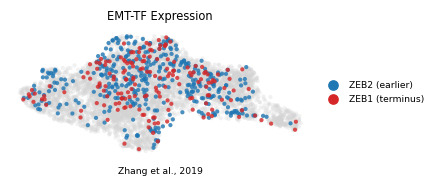

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
lab = {lo_tf: f'{lo_tf} (earlier)', hi_tf: f'{hi_tf} (terminus)'}
thr = {}
for g in [lo_tf, hi_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [lo_tf, hi_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [lo_tf, hi_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [lo_tf, hi_tf]})
order = sorted([lo_tf, hi_tf], key=lambda g: -int(sel[g].sum()))
colors = {lo_tf:'tab:blue', hi_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([],[],marker='o',ls='',color=colors[lo_tf],label=lab[lo_tf]),
                   Line2D([],[],marker='o',ls='',color=colors[hi_tf],label=lab[hi_tf])],
          frameon=False, loc='center left', bbox_to_anchor=(1.02,.5), fontsize=6)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5,-.14,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [lo_tf, hi_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')